# 02 - The Textbook Interval and Why It Fails  *(showpiece)*

The normal-theory interval is `prediction +/- z * residual_std`: **one constant width**
for every prediction. It is correct only when errors are constant-variance, symmetric
and normal. We confirm it on its home turf, then break each assumption and watch
coverage - overall and **by region** - against known truth.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

In [2]:
from src.datasets.synthetic import make_synthetic
from src.intervals.normal import NormalInterval
from src.evaluation.coverage import coverage
from src.evaluation.conditional import conditional_coverage
from src.visualisation import plot_intervals, plot_conditional_coverage

def split(structure, n=6000, n_tr=4000, seed=SEED):
    d = make_synthetic(structure, n, seed)
    return d.x[:n_tr], d.y[:n_tr], d.x[n_tr:], d.y[n_tr:]

## Homoscedastic data: this is the normal interval's home, and it works

Homoscedastic overall coverage: 0.895


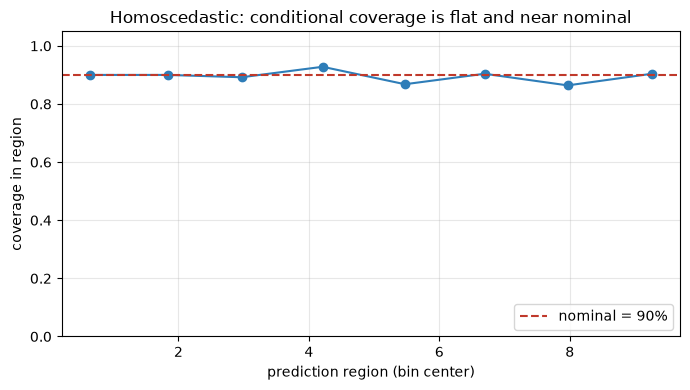

In [3]:
x_tr, y_tr, x_te, y_te = split("homoscedastic")
nm = NormalInterval(coverage=NOMINAL).fit(x_tr, y_tr)
lo, hi = nm.predict_interval(x_te)
cov_homo = coverage(y_te, lo, hi)
cond_homo = conditional_coverage(y_te, lo, hi, by=x_te.ravel(), n_bins=8)
print(f"Homoscedastic overall coverage: {cov_homo:.3f}")

fig = plot_conditional_coverage(cond_homo, nominal=NOMINAL)
fig.axes[0].set_title("Homoscedastic: conditional coverage is flat and near nominal")
save_fig(fig, "02_homoscedastic_conditional")
plt.show()

## Heteroscedastic data: the single constant width breaks

Overall coverage dips below nominal - but the real tell is the **conditional** plot:
too wide (overcovering) in the calm region, far too narrow (undercovering) in the
volatile one, failing exactly where the stakes are highest.

Heteroscedastic overall coverage: 0.881
  volatile-region coverage: 0.656
  calm-region coverage:     1.000


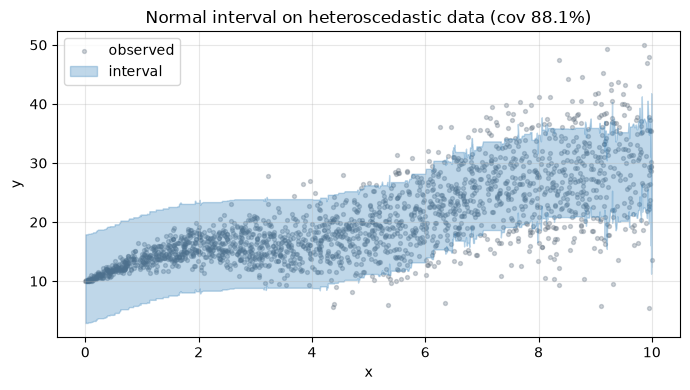

In [4]:
x_tr, y_tr, x_te, y_te = split("heteroscedastic")
nm = NormalInterval(coverage=NOMINAL).fit(x_tr, y_tr)
lo, hi = nm.predict_interval(x_te)
cov_hetero = coverage(y_te, lo, hi)
cond_hetero = conditional_coverage(y_te, lo, hi, by=x_te.ravel(), n_bins=8)
print(f"Heteroscedastic overall coverage: {cov_hetero:.3f}")
print(f"  volatile-region coverage: {cond_hetero['coverage'].min():.3f}")
print(f"  calm-region coverage:     {cond_hetero['coverage'].max():.3f}")

fig = plot_intervals(x_te, y_te, lo, hi, title=f"Normal interval on heteroscedastic data (cov {cov_hetero:.1%})")
save_fig(fig, "02_heteroscedastic_band")
plt.show()

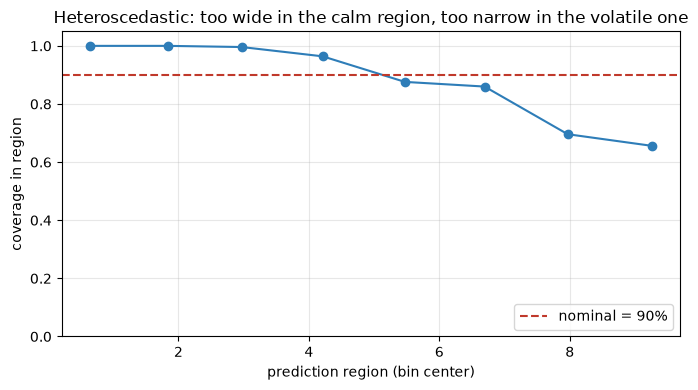

In [5]:
fig = plot_conditional_coverage(cond_hetero, nominal=NOMINAL)
fig.axes[0].set_title("Heteroscedastic: too wide in the calm region, too narrow in the volatile one")
save_fig(fig, "02_heteroscedastic_conditional")
plt.show()

## Skewed errors: a symmetric interval is the wrong shape

Skewed overall coverage: 0.909 (residuals are not symmetric)


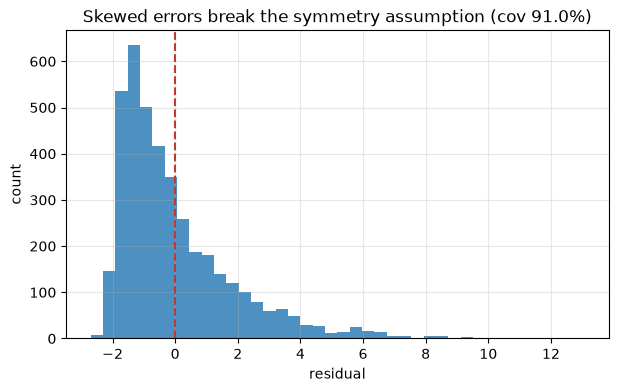

In [6]:
x_tr, y_tr, x_te, y_te = split("skewed")
nm = NormalInterval(coverage=NOMINAL).fit(x_tr, y_tr)
lo, hi = nm.predict_interval(x_te)
cov_skew = coverage(y_te, lo, hi)
resid = y_tr - nm._model.predict(x_tr)
print(f"Skewed overall coverage: {cov_skew:.3f} (residuals are not symmetric)")

fig, ax = plt.subplots()
ax.hist(resid, bins=40, color="#2E7DB8", alpha=0.85)
ax.axvline(0.0, color="#C0392B", ls="--")
ax.set_title(f"Skewed errors break the symmetry assumption (cov {cov_skew:.1%})")
ax.set_xlabel("residual"); ax.set_ylabel("count")
save_fig(fig, "02_skewed_residuals")
plt.show()

In [7]:
save_json("02_textbook_interval", {
    "nominal_coverage": NOMINAL,
    "homoscedastic": {
        "overall_coverage": float(cov_homo),
        "conditional": cond_homo.to_dict(orient="records"),
    },
    "heteroscedastic": {
        "overall_coverage": float(cov_hetero),
        "volatile_region_coverage": float(cond_hetero["coverage"].min()),
        "calm_region_coverage": float(cond_hetero["coverage"].max()),
        "conditional": cond_hetero.to_dict(orient="records"),
    },
    "skewed": {"overall_coverage": float(cov_skew)},
})

PosixPath('/workspaces/prediction_intervals_arena/outputs/data/02_textbook_interval.json')

The default interval fails in the exact conditions real data presents. Next: methods
whose width is allowed to vary.